
Temperatura actual: 20
Puerta de olvido f: 0.8807970779778823
Puerta de entrada i: 0.8807970779778823
Candidato de memoria: 0.9640275800758169
Memoria anterior: 0.0
Nueva memoria C: 0.8491126756208685
Puerta de salida o: 0.8807970779778823
Nuevo estado h: 0.6082834181835157

Temperatura actual: 21
Puerta de olvido f: 0.9171425847837719
Puerta de entrada i: 0.9171425847837719
Candidato de memoria: 0.9838084368881592
Memoria anterior: 0.8491126756208685
Nueva memoria C: 1.6810500068312764
Puerta de salida o: 0.9171425847837719
Nuevo estado h: 0.8556919026635692

Temperatura actual: 23
Puerta de olvido f: 0.9386499107251441
Puerta de entrada i: 0.9386499107251441
Candidato de memoria: 0.9914925033330148
Memoria anterior: 1.6810500068312764
Nueva memoria C: 2.5085817885748645
Puerta de salida o: 0.9386499107251441
Nuevo estado h: 0.9262978274866307


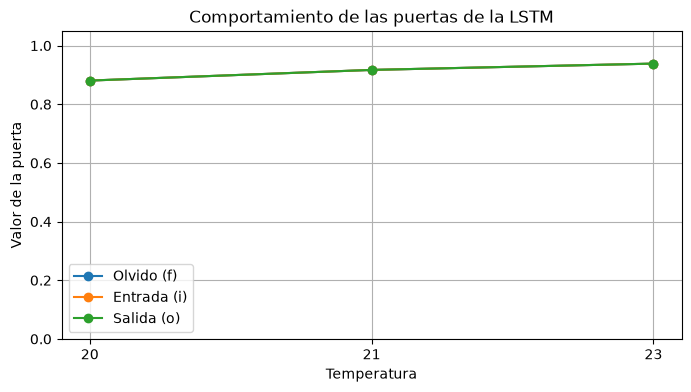

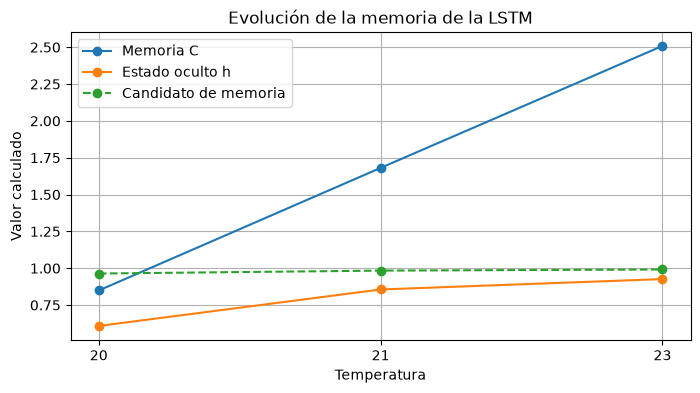

In [1]:

import numpy as np
import matplotlib.pyplot as plt

temperaturas = [20, 21, 23]

# Memoria y estado iniciales
C = 0.0
h = 0.0

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Aquí guardamos los resultados
historial = {
    "f": [], "i": [], "candidato": [],
    "C": [], "o": [], "h": []
}

for x in temperaturas:

    print("\n==============================")
    print("Temperatura actual:", x)

    # Puerta de olvido
    f = sigmoid(0.1 * x + 0.5 * h)
    print("Puerta de olvido f:", f)

    # Puerta de entrada
    i = sigmoid(0.1 * x + 0.5 * h)
    print("Puerta de entrada i:", i)

    # Candidato de memoria
    C_nueva = np.tanh(0.1 * x + 0.5 * h)
    print("Candidato de memoria:", C_nueva)

    # Actualizar memoria
    C_anterior = C
    C = f * C + i * C_nueva
    print("Memoria anterior:", C_anterior)
    print("Nueva memoria C:", C)

    # Puerta de salida
    o = sigmoid(0.1 * x + 0.5 * h)
    print("Puerta de salida o:", o)

    # Nuevo estado oculto
    h = o * np.tanh(C)
    print("Nuevo estado h:", h)

    # Guardar los resultados
    historial["f"].append(f)
    historial["i"].append(i)
    historial["candidato"].append(C_nueva)
    historial["C"].append(C)
    historial["o"].append(o)
    historial["h"].append(h)

# Eje horizontal: cada temperatura procesada
pasos = range(len(temperaturas))

# GRAFICA 1: Las tres puertas
plt.figure(figsize=(8, 4))

plt.plot(pasos, historial["f"], marker="o", label="Olvido (f)")
plt.plot(pasos, historial["i"], marker="o", label="Entrada (i)")
plt.plot(pasos, historial["o"], marker="o", label="Salida (o)")

plt.xticks(pasos, temperaturas)
plt.ylim(0, 1.05)
plt.xlabel("Temperatura")
plt.ylabel("Valor de la puerta")
plt.title("Comportamiento de las puertas de la LSTM")
plt.grid(True)
plt.legend()
plt.show()

# GRAFICA 2: Memoria y estado oculto
plt.figure(figsize=(8, 4))

plt.plot(pasos, historial["C"], marker="o", label="Memoria C")
plt.plot(pasos, historial["h"], marker="o", label="Estado oculto h")
plt.plot(pasos, historial["candidato"], marker="o",
         linestyle="--", label="Candidato de memoria")

plt.xticks(pasos, temperaturas)
plt.xlabel("Temperatura")
plt.ylabel("Valor calculado")
plt.title("Evolución de la memoria de la LSTM")
plt.grid(True)
plt.legend()
plt.show()
